# Лабораторная работа №1

Ubuntu Dialogue Corpus: очистка, нормализация и биграммная модель.

In [ ]:
from __future__ import annotations

import html
import json
import math
import random
import re
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer, WordNetLemmatizer
from sklearn.model_selection import train_test_split

from prepare_data import prepare

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT / 'text-analyse' / 'lab1'
OUT = ROOT / 'results'
nltk.data.path.insert(0, str(ROOT / 'nltk_data'))
SEED = 42


from IPython.display import display
OUT.mkdir(exist_ok=True)

## Функции и модель
Правила очистки, Левенштейн, биграммная модель и проверки.

In [ ]:
RULES = [
    ('URL', re.compile(r'\b(?:https?://|ftp://|www\.)[^\s<>]+', re.I)),
    ('EMAIL', re.compile(r'\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b', re.I)),
    ('IP', re.compile(r'\b(?:\d{1,3}\.){3}\d{1,3}\b')),
    ('HEX', re.compile(r'\b0x[0-9a-f]+\b', re.I)),
    ('PATH', re.compile(r'(?<!\w)(?:~?/)(?:[\w.+~-]+/)*[\w.+~-]+')),
    ('VERSION', re.compile(r'\b\d+(?:\.\d+)+(?:[-\w.]*)\b')),
    ('NUM', re.compile(r'(?<![\w-])\d+(?:[.,]\d+)?(?![\w-])')),
]
TOKEN = re.compile(r'\[[A-Z]+\]|[a-z]+(?:[\x27’][a-z]+)+|[a-z0-9_]+(?:[.+-][a-z0-9_]+)*|[^\w\s]', re.I)
WORD = re.compile(r'[a-z]+(?:\x27[a-z]+)?\Z')

In [3]:
def clean(text: str, participants: set[str]) -> list[str]:
    text = html.unescape(text).lower()
    text = re.sub(r'</?(?:p|br|a|div|span|b|i|code)(?:\s[^>]*)?/?>', ' ', text)
    text = re.sub(r'[\x00-\x08\x0b\x0c\x0e-\x1f\u200b-\u200f\ufeff]', ' ', text)
    for name, pattern in RULES:
        text = pattern.sub(' [' + name + '] ', text)
    tokens = TOKEN.findall(text)
    tokens = ['[USER]' if t in participants else t for t in tokens]
    return ['<s>', *tokens, '</s>']

In [4]:
def levenshtein(a: str, b: str) -> int:
    """Левенштейн: время O(mn), память O(min(m,n))."""
    if len(a) < len(b):
        a, b = b, a
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        current = [i]
        for j, cb in enumerate(b, 1):
            current.append(min(current[-1] + 1, previous[j] + 1, previous[j - 1] + (ca != cb)))
        previous = current
    return previous[-1]

In [5]:
class BigramLM:
    def __init__(self, documents: list[list[str]], min_count: int = 2):
        raw = Counter(t for doc in documents for t in doc if t != '<s>')
        self.vocab = {t for t, n in raw.items() if n >= min_count} | {'[UNK]', '</s>'}
        self.vocab.discard('<s>')
        self.words = sorted(self.vocab)
        self.bigrams = Counter()
        self.contexts = Counter()
        self.next_words = defaultdict(Counter)
        for doc in documents:
            mapped = [doc[0]] + [self.map(t) for t in doc[1:]]
            for a, b in zip(mapped, mapped[1:]):
                self.bigrams[a, b] += 1
                self.contexts[a] += 1
                self.next_words[a][b] += 1

    def map(self, token: str) -> str:
        return token if token in self.vocab else '[UNK]'

    def probability(self, a: str, b: str, alpha: float = 0) -> float:
        denominator = self.contexts[a] + alpha * len(self.vocab)
        return (self.bigrams[a, b] + alpha) / denominator if denominator else 0.0

    def evaluate(self, docs: list[list[str]], alpha: float) -> dict:
        log_likelihood = 0.0
        total = zeros = oov = 0
        for doc in docs:
            mapped = ['<s>'] + [self.map(t) for t in doc[1:]]
            oov += sum(t not in self.vocab for t in doc[1:])
            for a, b in zip(mapped, mapped[1:]):
                total += 1
                p = self.probability(a, b, alpha)
                if p == 0:
                    zeros += 1
                else:
                    log_likelihood += math.log(p)
        # <s> — контекст; </s> учитывается в оценке.
        return dict(alpha=alpha, tokens=total, oov=oov, zero_transitions=zeros,
                    log_likelihood=None if zeros else log_likelihood,
                    perplexity=None if zeros else math.exp(-log_likelihood / total))

    def generate(self, rng: random.Random, alpha: float = 0.1, max_length: int = 40) -> list[str]:
        result = ['<s>']
        for _ in range(max_length):
            context = result[-1]
            c = self.contexts[context]
            if rng.random() < c / (c + alpha * len(self.vocab)):
                counts = self.next_words[context]
                token = rng.choices(list(counts), weights=list(counts.values()))[0]
            else:
                token = rng.choice(self.words)
            result.append(token)
            if token == '</s>':
                break
        return result

In [6]:
def save_table(name: str, rows) -> pd.DataFrame:
    df = pd.DataFrame(rows)
    df.to_csv(OUT / (name + '.csv'), index=False, encoding='utf-8-sig')
    return df

In [7]:
def md_table(df: pd.DataFrame) -> str:
    def fmt(v):
        return str(v).replace('|', '\\|').replace('\n', ' ')
    return '| ' + ' | '.join(map(str, df.columns)) + ' |\n|' + '|'.join(['---'] * len(df.columns)) + '|\n' + '\n'.join('| ' + ' | '.join(fmt(v) for v in row) + ' |' for row in df.itertuples(index=False, name=None))

In [8]:
def verify_core():
    for a, b, expected in [('', '', 0), ('', 'abc', 3), ('kitten', 'sitting', 3), ('ubuntu', 'ubntu', 1), ('ab', 'ba', 2)]:
        assert levenshtein(a, b) == expected == levenshtein(b, a)
    doc = clean('bob: https://ubuntu.com /etc/apt 0xFF 1.2.3 42 sudo apt-get', {'bob'})
    assert {'[USER]', '[URL]', '[PATH]', '[HEX]', '[VERSION]', '[NUM]', 'sudo', 'apt-get'} <= set(doc)
    tiny = BigramLM([['<s>', 'a', 'b', '</s>'], ['<s>', 'a', 'c', '</s>']])
    for a in ['<s>', 'a', '[UNK]', 'absent']:
        assert math.isclose(sum(tiny.probability(a, b, .1) for b in tiny.vocab), 1)
    assert tiny.evaluate([['<s>', 'a', 'b', '</s>']], 0)['perplexity'] == 1
    assert tiny.evaluate([['<s>', 'new', '</s>']], 0)['perplexity'] is None
    distinct = BigramLM([['<s>', 'a', 'b', '</s>'], ['<s>', 'a', 'c', '</s>']], min_count=1)
    # Ручная проверка: P=1/2, N=3, PPL=2**(1/3).
    assert math.isclose(distinct.evaluate([['<s>', 'a', 'b', '</s>']], 0)['perplexity'], 2 ** (1 / 3))

## 1. Данные и разбиение
Документ — реплика. Данные разделяем по целым диалогам 80/20. Класса нет: страты — длины диалогов.

In [9]:
OUT.mkdir(exist_ok=True)

verify_core()

prepare()

manifest = json.loads((ROOT / 'data/manifest.json').read_text(encoding='utf-8'))
(OUT / 'source_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')

df = pd.read_csv(ROOT / 'data/sample.csv.gz', dtype=str, keep_default_na=False)
empty = int(df.text.str.strip().eq('').sum())
exact_duplicates = int(df.duplicated(subset=['group_id', 'date', 'from', 'to', 'text']).sum())

# Повторные сообщения сохраняем.
df = df.loc[df.text.str.strip().ne('')].copy()

groups = df.groupby('group_id', sort=True).size().rename('utterances').to_frame()
groups['stratum'] = pd.cut(groups.utterances, [0, 5, 10, 20, float('inf')], labels=['1-5', '6-10', '11-20', '21+']).astype(str)

train_ids, test_ids = train_test_split(groups.index, test_size=.2, random_state=SEED, stratify=groups.stratum)

assert not set(train_ids) & set(test_ids)

groups['split'] = np.where(groups.index.isin(train_ids), 'Train', 'Test')
groups.to_csv(OUT / 'split_manifest.csv', encoding='utf-8-sig')

train = df.loc[df.group_id.isin(train_ids)].copy()
test = df.loc[df.group_id.isin(test_ids)].copy()

print(f'Train {len(train):,}, Test {len(test):,}', flush=True)
split_table = save_table('split_counts', [dict(split=s, dialogues=int((groups.split == s).sum()), utterances=len(part)) for s, part in [('Train', train), ('Test', test)]])

strata = pd.crosstab(groups.stratum, groups.split)
strata.to_csv(OUT / 'strata.csv', encoding='utf-8-sig')

display(split_table.rename(columns={'split':'Выборка','dialogues':'Диалоги','utterances':'Реплики'}))
display(strata)

Train 133,997, Test 32,923


,Выборка,Диалоги,Реплики
0,Train,14804,133997
1,Test,3702,32923


split,Test,Train
stratum,,
1-5,1656,6622
11-20,689,2754
21+,249,995
6-10,1108,4433


## 2. Статистики Train

In [ ]:
words = train.text.str.split().str.len()
chars = train.text.str.len()
stats = dict(documents=len(train), mean_words=float(words.mean()), mean_characters=float(chars.mean()), median_words=float(words.median()), max_words=int(words.max()))

stop = set(stopwords.words('english'))
stop_counts = Counter(w for text in train.text for w in re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower()) if w in stop)
top_stop = save_table('top30_stopwords', [dict(word=w, count=n) for w, n in stop_counts.most_common(30)])

display(pd.DataFrame([stats]).rename(columns={'documents':'Реплики','mean_words':'Среднее слов','mean_characters':'Среднее символов','median_words':'Медиана слов','max_words':'Максимум слов'}))

,Реплики,Среднее слов,Среднее символов,Медиана слов,Максимум слов
0,133997,9.991142,54.100413,8.0,95


## Распределение длин
Логарифмическая ось X; длинные реплики сохраняются.

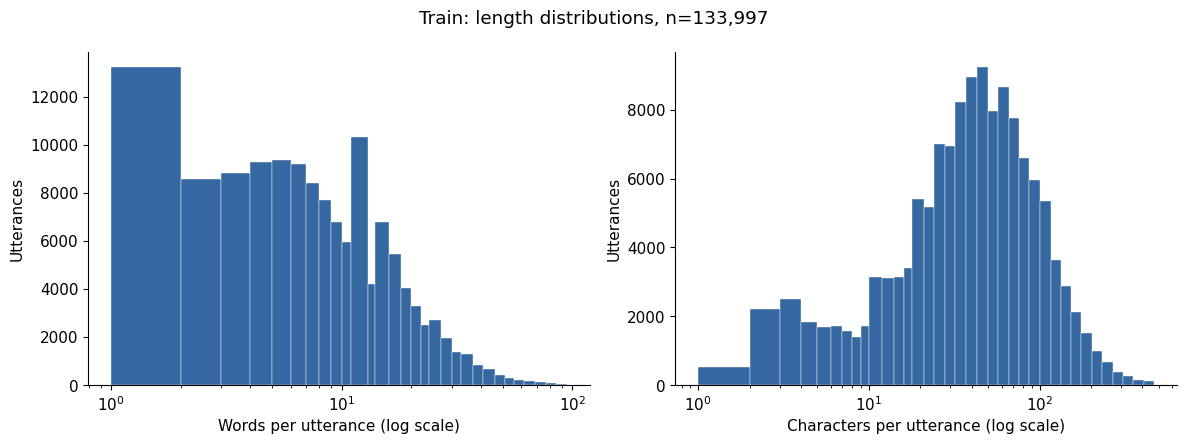

In [11]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, values, label in [(axes[0], words, 'Words per utterance'), (axes[1], chars, 'Characters per utterance')]:
    bins = np.unique(np.geomspace(1, max(2, values.max()), 45).astype(int))
    ax.hist(values.clip(lower=1), bins=bins, color='#3567A0', edgecolor='white', linewidth=.3)
    ax.set_xscale('log')
    ax.set_xlabel(label + ' (log scale)')
    ax.set_ylabel('Utterances')

fig.suptitle(f'Train: length distributions, n={len(train):,}')
fig.tight_layout()
fig.savefig(OUT / 'lengths.png', dpi=150)
plt.show()
plt.close(fig)

## Топ-30 стоп-слов
Для анализа используем список NLTK. В модели стоп-слова сохраняются.

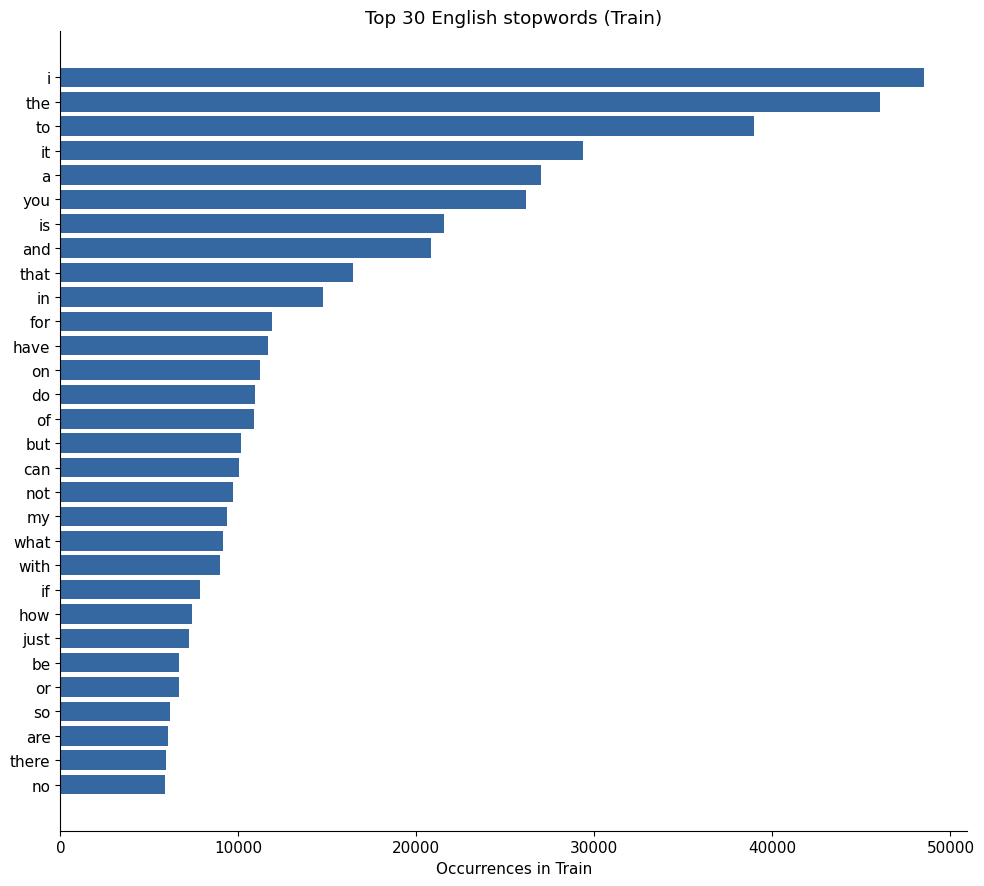

In [12]:
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top_stop.word[::-1], top_stop['count'][::-1], color='#3567A0')
ax.set(xlabel='Occurrences in Train', title='Top 30 English stopwords (Train)')
fig.tight_layout()
fig.savefig(OUT / 'stopwords.png', dpi=150)
plt.show()
plt.close(fig)

## 3. Типы шума
У каждого типа собственное правило. Категории могут пересекаться.

In [ ]:
noise_rows = []

for name, pattern in RULES:
    mask = train.text.str.contains(pattern)
    examples = train.loc[mask, 'text'].head(3).tolist()
    noise_rows.append(dict(type=name, documents=int(mask.sum()), share=float(mask.mean()), examples=json.dumps(examples, ensure_ascii=False)))

noise = save_table('noise', noise_rows)
assert (noise.documents > 0).sum() >= 3

display(noise[['type','documents','share']])

,type,documents,share
0,URL,3346,0.024971
1,EMAIL,38,0.000284
2,IP,332,0.002478
3,HEX,29,0.000216
4,PATH,8458,0.063121
5,VERSION,3913,0.029202
6,NUM,10971,0.081875


## 4. Конвейер очистки
Применяем clean(): отдельные замены, токенизация и границы <s>, </s>.

In [ ]:
participants = {v.lower() for col in ['from', 'to'] for v in train[col] if v}

train_docs = [clean(t, participants) for t in train.text]
test_docs = [clean(t, participants) for t in test.text]

save_table('cleaning_examples', [dict(before=t, after=' '.join(d)) for t, d in zip(train.text.head(15), train_docs[:15])])

display(pd.read_csv(OUT / 'cleaning_examples.csv').head(8))

,before,after
0,lol mwe only one person in the sound departmen...,<s> lol [USER] only one person in the sound de...
1,its so silly I installed the first time everyt...,<s> its so silly i installed the first time ev...
2,"Hi, I am adding a second drive to my machine b...","<s> hi , i am adding [USER] second drive to my..."
3,two drives open up clever posibilities to incr...,<s> two drives open up [USER] posibilities to ...
4,I already have a drive running with the system...,<s> i already have [USER] drive running with t...
5,im still a newb so im weary of console,<s> im still [USER] newb so im weary of consol...
6,/dev/hdb1,<s> [PATH] </s>
7,I have to dvd writers on second channel,<s> i have to dvd writers on second channel </s>


## 5. Стемминг и лемматизация
Snowball — стемминг; WordNet с частями речи — лемматизация. Технические токены не изменяем.

In [ ]:
print('Normalization and POS tagging...', flush=True)

stemmer = SnowballStemmer('english')
lemmatizer = WordNetLemmatizer()

lexical_docs = [[t for t in doc[1:-1] if WORD.fullmatch(t)] for doc in train_docs]
lexical = Counter(t for doc in lexical_docs for t in doc)
stem_vocab = {stemmer.stem(t) for t in lexical}

lemma_vocab = set()
lemma_examples = {}
pos_map = {'J': 'a', 'V': 'v', 'N': 'n', 'R': 'r'}

for batch_start in range(0, len(lexical_docs), 2000):
    for tagged in nltk.pos_tag_sents(lexical_docs[batch_start:batch_start + 2000]):
        for token, pos in tagged:
            lemma = lemmatizer.lemmatize(token, pos_map.get(pos[0], 'n'))
            lemma_vocab.add(lemma)
            if lemma != token and len(lemma_examples) < 30:
                lemma_examples[token] = lemma

full_vocab = {t for doc in train_docs for t in doc}
protected = {t for t in full_vocab if not WORD.fullmatch(t)}

normalization = save_table('normalization', [dict(method=m, lexical_vocabulary=len(v), total_vocabulary=len(v | protected)) for m, v in [('Original', set(lexical)), ('Snowball', stem_vocab), ('WordNet_POS', lemma_vocab)]])
save_table('normalization_examples', [dict(token=w, stem=stemmer.stem(w), lemma=l) for w, l in lemma_examples.items()])

display(normalization.replace({'method':{'Original':'Без нормализации','Snowball':'Стемминг (Snowball)','WordNet_POS':'Лемматизация (WordNet + части речи)'}}).rename(columns={'method':'Метод','lexical_vocabulary':'Уникальные слова','total_vocabulary':'Все уникальные токены'}))
display(pd.read_csv(OUT / 'normalization_examples.csv').head(10))

Normalization and POS tagging...


,Метод,Уникальные слова,Все уникальные токены
0,Без нормализации,29126,37458
1,Стемминг (Snowball),22409,30741
2,Лемматизация (WordNet + части речи),26330,34662


,token,stem,lemma
0,its,it,it
1,installed,instal,instal
2,worked,work,work
3,reinstalled,reinstal,reinstall
4,am,am,be
5,adding,ad,add
6,as,as,a
7,drives,drive,drive
8,is,is,be
9,writers,writer,writer


## 6. Левенштейн
Собственный алгоритм с двумя строками памяти. Поиск ограничен 700 частыми словами; близость не доказывает опечатку.

In [ ]:
print('Levenshtein pairs...', flush=True)

candidates = [w for w, n in lexical.most_common() if 4 <= len(w) <= 18 and n >= 5][:700]
pairs = []

for a, b in combinations(candidates, 2):
    if abs(len(a) - len(b)) <= 2:
        distance = levenshtein(a, b)
        if distance in (1, 2):
            pairs.append(dict(word1=a, word2=b, distance=distance, count1=lexical[a], count2=lexical[b], score=min(lexical[a], lexical[b])))

pairs.sort(key=lambda r: (-r['score'], r['distance'], r['word1'], r['word2']))
pair_table = save_table('top10_pairs', pairs[:10])

display(pair_table)

Levenshtein pairs...


,word1,word2,distance,count1,count2,score
0,that,this,2,16432,5736,5736
1,that,then,2,16432,4695,4695
2,there,then,2,5910,4695,4695
3,this,then,2,5736,4695,4695
4,then,when,1,4695,3826,3826
5,install,installed,2,6261,2791,2791
6,should,would,2,3040,2705,2705
7,thanks,think,2,2753,2542,2542
8,then,think,2,4695,2542,2542
9,this,think,2,5736,2542,2542


## 7–8. Биграммы и перплексия
Словарь обучаем только на Train. Редкие и неизвестные токены заменяем [UNK]. Сравниваем MLE, Лапласа и Линдстона.

In [17]:
print('Language model...', flush=True)

model = BigramLM(train_docs)
(OUT / 'vocabulary.json').write_text(json.dumps(model.words, ensure_ascii=False, indent=2), encoding='utf-8')

evaluations = [model.evaluate(test_docs, a) for a in [0, 1, .1]]
save_table('perplexity', [{**r, 'perplexity': 'infinity' if r['perplexity'] is None else r['perplexity']} for r in evaluations])

display(pd.read_csv(OUT / 'perplexity.csv').replace({'perplexity':{'infinity':'∞'}}))

Language model...


,alpha,tokens,oov,zero_transitions,log_likelihood,perplexity
0,0.0,420606,9141,43696,NaN,inf
1,1.0,420606,9141,0,-2.537114e+06,416.565393
2,0.1,420606,9141,0,-2.217876e+06,195.009462


## Проверка вероятностей
Проверяем суммы вероятностей и число обучающих переходов.

In [18]:
checked_contexts = ['<s>', '[UNK]', '__unseen_context__'] + list(model.contexts.most_common(10)[i][0] for i in range(10))

for context in checked_contexts:
    for alpha in [1, .1]:
        assert math.isclose(sum(model.probability(context, w, alpha) for w in model.words), 1, abs_tol=1e-10)

assert model.contexts['<s>'] == len(train_docs)
assert sum(model.bigrams.values()) == sum(len(d) - 1 for d in train_docs)

print('Проверки пройдены')

Проверки пройдены


## 9. Генерация
Пять реплик с seed=42, α=0.1. Остановка на </s> или после 40 токенов.

In [19]:
rng = random.Random(SEED)
generated = [' '.join(model.generate(rng)) for _ in range(5)]
(OUT / 'generated.txt').write_text('\n\n'.join(generated), encoding='utf-8')

for i, text in enumerate(generated, 1):
    print(f'{i}. {text}\n')

1. <s> i got ra mozplugger indian bane99 lvl netcat predefined includes older ubunta sucess indonesia clean sites-available bag gpart overlooked ahci mkfs.xfs weechat myipaddress php5 truthful crysis al so i want to know that pppoe plastic safest kill when you dont

2. <s> but it , yeah </s>

3. <s> personally either behaving sent v10 greate caracters background true [UNK] [UNK] . midori n'est 384mb boinc mmm smartctl bloat cloning xlib rockfire loose maching ubuntu-irc throughput painfully hai modprobe weeks + lime wich territory dmg2iso unchecked ate libtcl silently btu

4. <s> no i just plug d78 how'd predefined variables brake appdb.winehq.org okay okej aren anser vice-versa fro divert libsdl_net bzr universities last.fm lasts cron.allow processed inferface tulip qualified powerbooks hum stress drapper mkinitrd indian kind wengo suing music-applet prerelease theora balloon

5. <s> besides libsnmp5 turkey anouther 10 elaborate speeding inetd samething natively license faik another m

## Сохранение результатов
Сохраняем вычисленные показатели в results/summary.json.

In [ ]:
summary = dict(seed=SEED, stats=stats, empty_removed=empty, duplicate_records_retained=exact_duplicates,
               vocabulary_size=len(model.vocab), evaluations=evaluations, generated=generated,
               pair_search_candidates=len(candidates), checks='core boundary tests, split disjointness, probability normalization, transition totals: passed')

(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

2180

: 